In [6]:
import json
from pathlib import Path
from tempfile import NamedTemporaryFile

import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import trange

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebook":
    PROJECT_ROOT = PROJECT_ROOT.parent

SOURCE_ROOT = Path("/share/data/wuyd")
RAW = SOURCE_ROOT / "rawdata"
BC_PROCESSED = SOURCE_ROOT / "SpaPAD" / "processed" / "BC"
DATA_ROOT = PROJECT_ROOT / "data"
EPOCHS = 500
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PATCH_SIZE = 16
VISIUM_SIZE = (round(PATCH_SIZE * 8000 / 55),) * 2
BC_ST_SIZE = (round(PATCH_SIZE * 6200 / 100), round(PATCH_SIZE * 6600 / 100))

In [7]:
class SmallPatchAutoencoder(nn.Module):
    def __init__(self, embedding_dim=128):
        super(SmallPatchAutoencoder, self).__init__()

        # Encoder: 轻量卷积结构，避免过度下采样
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),  # 16x16 → 16x16
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), # 16x16 → 8x8
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),# 8x8 → 4x4
            nn.ReLU(),
            nn.Flatten(),  # 4x4x128 = 2048
            nn.Linear(2048, embedding_dim)
        )

        # Decoder: MLP 解码为 16x16x3
        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, 1024),
            nn.ReLU(),
            nn.Linear(1024, 2048),
            nn.ReLU(),
            nn.Linear(2048, 768),  # 16*16*3
            nn.Sigmoid()
        )

    def forward(self, x):
        embedding = self.encoder(x)
        reconstruction = self.decoder(embedding)
        reconstruction = reconstruction.view(-1, 3, 16, 16)
        return reconstruction, embedding

In [8]:
def crop_spots(image, xy, barcodes, target_size, section):
    xy = np.asarray(xy, dtype=float)
    if barcodes.empty or barcodes.has_duplicates or barcodes.hasnans:
        raise ValueError(f'{section}: empty, duplicate or missing barcodes')
    if xy.shape != (len(barcodes), 2) or not np.isfinite(xy).all():
        raise ValueError(f'{section}: expected one finite (x, y) per barcode')

    # PIL sizes are (width, height). NumPy images are indexed [y, x].
    scale_xy = np.asarray(target_size) / image.size
    centers = np.rint(xy * scale_xy).astype(int)
    if ((xy < 0) | (xy >= image.size)).any():
        raise ValueError(f'{section}: spot center outside the source image')
    resized = image.resize(target_size)
    radius = PATCH_SIZE // 2
    padded = np.pad(np.asarray(resized), ((radius, radius), (radius, radius), (0, 0)),
                    mode='constant', constant_values=255)
    # Padding shifts (x, y) by radius, so the patch starts at [y, x].
    patches = np.stack([padded[y:y + PATCH_SIZE, x:x + PATCH_SIZE] for x, y in centers])

    fig, ax = plt.subplots()
    ax.imshow(resized)
    boxes = [Rectangle((x - radius - 0.5, y - radius - 0.5), PATCH_SIZE, PATCH_SIZE)
             for x, y in centers]
    ax.add_collection(PatchCollection(boxes, facecolor='none', edgecolor='red', linewidth=0.4))
    ax.set_title(f'{section} · {len(barcodes)} spots')
    plt.show()
    plt.close(fig)
    return torch.from_numpy(patches).permute(0, 3, 1, 2).float().div_(255)

In [9]:
def train_embedding(patches, section, seed):
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    dataset = TensorDataset(patches)
    train_loader = DataLoader(dataset, batch_size=64, shuffle=True)
    network = SmallPatchAutoencoder(embedding_dim=128).to(DEVICE)
    optimizer = torch.optim.Adam(network.parameters(), lr=5e-4)
    criterion = nn.MSELoss()
    history = []
    for _ in trange(EPOCHS, desc=section):
        total = 0.0
        network.train()
        for (batch,) in train_loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            reconstruction, _ = network(batch)
            loss = criterion(reconstruction, batch)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        history.append(total / len(dataset))

    fig, ax = plt.subplots()
    ax.plot(history)
    ax.set(xlabel='Epoch', ylabel='Reconstruction MSE', title=section)
    plt.show()
    plt.close(fig)

    network.eval()
    with torch.inference_mode():
        vectors = torch.cat([network.encoder(batch.to(DEVICE)).cpu()
                             for (batch,) in DataLoader(dataset, batch_size=64, shuffle=False)])
    if vectors.shape != (len(dataset), 128) or not torch.isfinite(vectors).all():
        raise ValueError(f"{section}: invalid embedding matrix")
    return vectors.numpy()

In [10]:
def visium_canvas(image):
    canvas = Image.new("RGB", (max(2000, image.width), max(2000, image.height)), "white")
    canvas.paste(image, (0, 0))
    return canvas


def write_image_embedding(path, barcodes, embedding):
    data = ad.read_h5ad(path)
    if data.obs_names.has_duplicates:
        raise ValueError(f"{path}: duplicate spot barcodes")
    rows = barcodes.get_indexer(data.obs_names)
    if (rows < 0).any():
        missing = data.obs_names[rows < 0]
        raise ValueError(f"{path}: {len(missing)} spots missing from the embedding, including {missing[0]}")
    data.obsm["image_embedding"] = embedding[rows]

    # Replace the original only after the H5AD write completes.
    with NamedTemporaryFile(dir=path.parent, prefix=f".{path.stem}.",
                            suffix=".h5ad", delete=False) as stream:
        temporary_path = Path(stream.name)
    try:
        data.write_h5ad(temporary_path, convert_strings_to_categoricals=False)
        temporary_path.chmod(path.stat().st_mode & 0o777)
        temporary_path.replace(path)
    finally:
        temporary_path.unlink(missing_ok=True)


def run_visium(section, folder, prefix, output, seed):
    with (folder / f'{prefix}scalefactors_json.json').open() as stream:
        scale = json.load(stream)['tissue_hires_scalef']
    positions = pd.read_csv(folder / f'{prefix}tissue_positions_list.csv', header=None,
                            names=['barcode', 'in_tissue', 'array_row', 'array_col', 'pixel_row', 'pixel_col'])
    spots = positions.loc[positions['in_tissue'] == 1].set_index('barcode')
    xy = spots[['pixel_col', 'pixel_row']].to_numpy() * scale
    with Image.open(folder / f'{prefix}tissue_hires_image.png') as source:
        image = visium_canvas(source.convert('RGB'))
    patches = crop_spots(image, xy, spots.index, VISIUM_SIZE, section)
    embedding = train_embedding(patches, section, seed)
    write_image_embedding(output, spots.index, embedding)

## BC

In [ ]:
section = "V07"
data = ad.read_h5ad(BC_PROCESSED / f"{section}.h5ad")
# The processed V07 coordinates already refer to the hires image.
hires = data.uns["spatial"][section]["images"]["hires"]
image = visium_canvas(Image.fromarray(hires))
patches = crop_spots(image, data.obsm["spatial"], data.obs_names, VISIUM_SIZE, section)
embedding = train_embedding(patches, section, seed=123)
write_image_embedding(DATA_ROOT / "BC" / f"{section}.h5ad", data.obs_names, embedding)

In [ ]:
section = "H1"
data = ad.read_h5ad(BC_PROCESSED / f"{section}.h5ad")
with Image.open(RAW / "BC" / "images" / "images" / "HE" / f"{section}.jpg") as image:
    patches = crop_spots(image.convert("RGB"), data.obsm["spatial"], data.obs_names,
                         BC_ST_SIZE, section)
embedding = train_embedding(patches, section, seed=123)
write_image_embedding(DATA_ROOT / "BC" / f"{section}.h5ad", data.obs_names, embedding)

## OSCC

In [ ]:
section = "GSM6339632_s2"
folder = RAW / "OSCC" / "visium"
output = DATA_ROOT / "OSCC" / f"{section}.h5ad"
run_visium(section, folder, f"{section}_", output, seed=123)

## CD

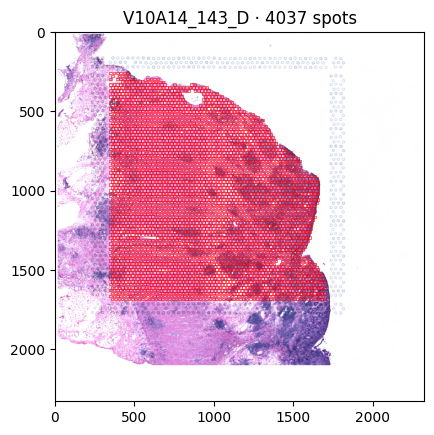

V10A14_143_D:   0%|          | 0/500 [00:00<?, ?it/s]

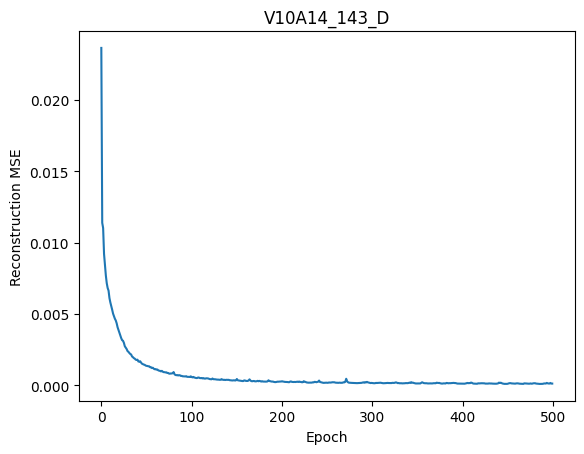

/home/wuyd/anaconda3/envs/env_SpaPAD/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


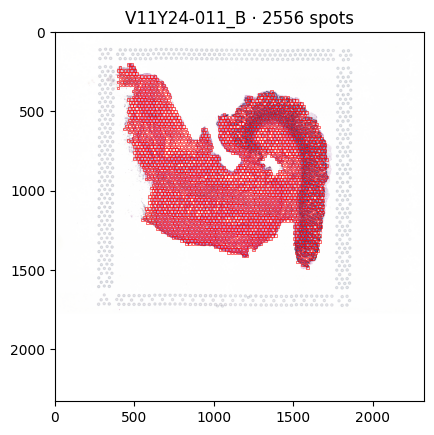

V11Y24-011_B:   0%|          | 0/500 [00:00<?, ?it/s]

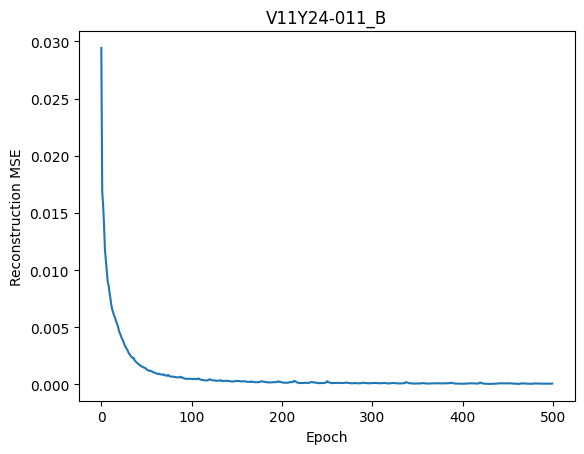

/home/wuyd/anaconda3/envs/env_SpaPAD/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [11]:
for section in ("V10A14_143_D", "V11Y24-011_B"):
    folder = RAW / "CD" / "visium" / section
    output = DATA_ROOT / "CD" / f"{section}.h5ad"
    run_visium(section, folder, f"{section}.", output, seed=123)